# Indian Monument Recognition with a CNN

Image classification of **49 Indian monuments** with a convolutional neural network built from scratch in TensorFlow/Keras (pretrained models were not allowed in this course project).

Dataset: [I-m-Parthian/Monument-Recognition](https://github.com/I-m-Parthian/Monument-Recognition) (cloned in the first cell).

## 1. Load the dataset

In [ ]:

!git clone https://github.com/I-m-Parthian/Monument-Recognition.git
import os

path = "Monument-Recognition/Dataset/1.Train"
print(os.listdir(path))  # Should show class folders

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.Resize((400, 400)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder("Monument-Recognition/Dataset/1.Train", transform=transform)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Show one batch
images, labels = next(iter(dataloader))
print(images.shape, labels)

Cloning into 'Monument-Recognition'...
remote: Enumerating objects: 2775, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 2775 (delta 8), reused 0 (delta 0), pack-reused 2760 (from 1)
Receiving objects: 100% (2775/2775), 28.60 MiB | 36.07 MiB/s, done.
Resolving deltas: 100% (2560/2560), done.
['hawa mahal', 'byzantine architecture', 'fortification', 'Diu Museum', 'bhoramdev mandir', 'charminar', 'chapora fort', 'fatehpur sikri', 'Aga Khan Palace', 'bharat mata mandir haridwar', 'Hampi', 'Hoshang Shah Tomb', 'Badrinath Temple', 'chittorgarh', 'city palace', 'Fatehpur Sikri Fort', 'Bhudha Temple', 'golden temple', 'basilica of bom jesus', 'Bekal', 'bara imambara', 'dome', 'Chandi Devi mandir hariwar', 'Cheese', 'diu', 'chandigarh college of architecture', 'Champaner', 'Brihadeshwara Temple', 'chhatisgarh ke saat ajube', 'hidimbi devi temple', 'barsi gate hansi old', 'ajmeri gate delhi', 'Isarlat Sargasooli', 'India Gate',

## 2. Model: 4 convolutional blocks + 2 dense layers

In [ ]:
from keras.models import Sequential
#from sklearn.externals import joblib
from keras.layers import Dense, Flatten, Conv2D, MaxPool2D, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import BatchNormalization
#from sklearn.model_selection import train_test_split
from keras.optimizers import  Adam

from tensorflow.keras.layers import Activation


In [ ]:

model = Sequential()
# Layer 1
model.add(Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(400, 400, 3)))
model.add(MaxPool2D(pool_size=(2, 2)))

# Layer 2
model.add(Conv2D(128, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D(pool_size=(2, 2)))

# Layer 3
model.add(Conv2D(256, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D(pool_size=(2, 2)))

# Layer 4
model.add(Conv2D(512, (3, 3), activation='relu', padding='same'))
model.add(MaxPool2D(pool_size=(2, 2)))

model.add(Flatten())

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.35))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.35))
model.add(Dense(49, activation='softmax'))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 3. Class distribution of the original training set

In [ ]:
from collections import Counter

# Get class names from dataset
class_names = dataset.classes  # List of class names
class_to_idx = dataset.class_to_idx  # Dictionary: class name -> index

# Get all labels from the dataset
all_labels = [label for _, label in dataset.imgs]  # Each item in dataset.imgs is (path, label)

# Count labels
label_counts = Counter(all_labels)

# Print results
for class_index, count in label_counts.items():
    class_name = class_names[class_index]
    print(f"Class '{class_name}': {count} images")


Class 'Aga Khan Palace': 39 images
Class 'Badrinath Temple': 27 images
Class 'Bekal': 39 images
Class 'Bhudha Temple': 36 images
Class 'Brihadeshwara Temple': 36 images
Class 'Cathederal': 35 images
Class 'Champaner': 38 images
Class 'Chandi Devi mandir hariwar': 36 images
Class 'Cheese': 39 images
Class 'Chhatrapati Shivaji terminus': 39 images
Class 'Chittorgarh Padmini Lake Palace': 40 images
Class 'Daman': 40 images
Class 'Diu Museum': 38 images
Class 'Fatehpur Sikri Fort': 42 images
Class 'Hampi': 40 images
Class 'Hoshang Shah Tomb': 40 images
Class 'India Gate': 41 images
Class 'Isarlat Sargasooli': 40 images
Class 'ajanta caves': 50 images
Class 'ajmeri gate delhi': 34 images
Class 'albert hall museum': 26 images
Class 'bara imambara': 36 images
Class 'barsi gate hansi old': 38 images
Class 'basilica of bom jesus': 38 images
Class 'bharat mata mandir haridwar': 38 images
Class 'bhoramdev mandir': 41 images
Class 'bidar fort': 42 images
Class 'buland darwaza': 53 images
Class 'by

## 4. Offline data augmentation

Each training image gets 5 augmented copies (rotation, zoom, horizontal flip, width/height shift), saved next to the originals. Note: the 80/20 train/validation split is taken *after* augmentation, so validation accuracy is optimistic. The separate test set below is the reliable measure.

In [ ]:
import os
import shutil
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
import numpy as np

# ------------------------------
# Settings
# ------------------------------
train_dir = 'Monument-Recognition/Dataset/1.Train'       # original training images
augmented_dir = 'Monument-Recognition/Dataset/1.Train_Augmented'  # folder for original + augmented images
num_augmented_images = 5   # augmented copies generated per image
target_size = (400, 400)   # image size after resizing
batch_size = 32            # training batch size
# ------------------------------

# Create the output folder
os.makedirs(augmented_dir, exist_ok=True)

# 1) Copy the original images
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    save_class_path = os.path.join(augmented_dir, class_name)
    os.makedirs(save_class_path, exist_ok=True)

    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            src_path = os.path.join(class_path, img_name)
            dst_path = os.path.join(save_class_path, img_name)
            try:
                shutil.copy(src_path, dst_path)  # copy original image
            except Exception as e:
                print(f"Failed to copy {img_name}: {e}")
                continue

# 2) Augmentation settings
datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# 3) Generate augmented copies for every class
for class_name in os.listdir(train_dir):
    class_path = os.path.join(train_dir, class_name)
    save_class_path = os.path.join(augmented_dir, class_name)

    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)
            try:
                # load image as an array
                img = load_img(img_path, target_size=target_size)
                x = img_to_array(img)
                x = np.expand_dims(x, axis=0)

                # generate and save augmented copies
                i = 0
                for batch in datagen.flow(
                    x,
                    batch_size=1,
                    save_to_dir=save_class_path,
                    save_prefix='aug',
                    save_format='jpg'
                ):
                    i += 1
                    if i >= num_augmented_images:  
                        break
            except Exception as e:
                print(f"Failed to load {img_name}: {e}")
                continue

print("Original and augmented images saved to:", augmented_dir)

# ------------------------------
# 4) Train/validation generators on the augmented folder
# ------------------------------
final_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train = final_datagen.flow_from_directory(
    augmented_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training'
)

validation = final_datagen.flow_from_directory(
    augmented_dir,
    target_size=target_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation'
)


Original and augmented images saved to: Monument-Recognition/Dataset/1.Train_Augmented
Found 9189 images belonging to 49 classes.
Found 2273 images belonging to 49 classes.


## 5. Training with early stopping

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)


history = model.fit(
    train,
    validation_data=validation,
    epochs=100,
    callbacks=[early_stopping]
)


Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


288/288 ━━━━━━━━━━━━━━━━━━━━ 208s 590ms/step - accuracy: 0.0577 - loss: 3.7598 - val_accuracy: 0.2860 - val_loss: 2.7917
Epoch 2/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 147s 510ms/step - accuracy: 0.2454 - loss: 2.9020 - val_accuracy: 0.5455 - val_loss: 1.8735
Epoch 3/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 148s 515ms/step - accuracy: 0.3941 - loss: 2.2361 - val_accuracy: 0.6876 - val_loss: 1.2729
Epoch 4/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 199s 507ms/step - accuracy: 0.5428 - loss: 1.6312 - val_accuracy: 0.7519 - val_loss: 0.9667
Epoch 5/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 148s 515ms/step - accuracy: 0.6552 - loss: 1.2343 - val_accuracy: 0.8069 - val_loss: 0.7333
Epoch 6/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 150s 519ms/step - accuracy: 0.7399 - loss: 0.8814 - val_accuracy: 0.8231 - val_loss: 0.6258
Epoch 7/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 150s 521ms/step - accuracy: 0.8165 - loss: 0.6374 - val_accuracy: 0.8579 - val_loss: 0.5245
Epoch 8/100
288/288 ━━━━━━━━━━━━━━━━━━━━ 151s 523ms/step - accuracy: 0.8493 - los

In [ ]:
model.save('model3.h5')


## 6. Class distribution after augmentation

In [ ]:
from collections import Counter
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Count images per class in the augmented folder
datagen = ImageDataGenerator(rescale=1./255)

dataset = datagen.flow_from_directory(
    'Monument-Recognition/Dataset/1.Train_Augmented',
    target_size=(400, 400),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

# class names and indices
class_names = list(dataset.class_indices.keys())  # List of class names
class_to_idx = dataset.class_indices                # Dictionary: class name -> index

# all labels
all_labels = dataset.classes  

# count labels
label_counts = Counter(all_labels)

# print results
for class_index, count in label_counts.items():
    class_name = class_names[class_index]
    print(f"Class '{class_name}': {count} images")



Found 11462 images belonging to 49 classes.
Class 'Aga Khan Palace': 231 images
Class 'Badrinath Temple': 161 images
Class 'Bekal': 233 images
Class 'Bhudha Temple': 213 images
Class 'Brihadeshwara Temple': 216 images
Class 'Cathederal': 209 images
Class 'Champaner': 225 images
Class 'Chandi Devi mandir hariwar': 215 images
Class 'Cheese': 231 images
Class 'Chhatrapati Shivaji terminus': 233 images
Class 'Chittorgarh Padmini Lake Palace': 239 images
Class 'Daman': 238 images
Class 'Diu Museum': 226 images
Class 'Fatehpur Sikri Fort': 249 images
Class 'Hampi': 239 images
Class 'Hoshang Shah Tomb': 237 images
Class 'India Gate': 244 images
Class 'Isarlat Sargasooli': 240 images
Class 'ajanta caves': 296 images
Class 'ajmeri gate delhi': 203 images
Class 'albert hall museum': 154 images
Class 'bara imambara': 216 images
Class 'barsi gate hansi old': 228 images
Class 'basilica of bom jesus': 227 images
Class 'bharat mata mandir haridwar': 228 images
Class 'bhoramdev mandir': 245 images
Cla

## 7. Training curves

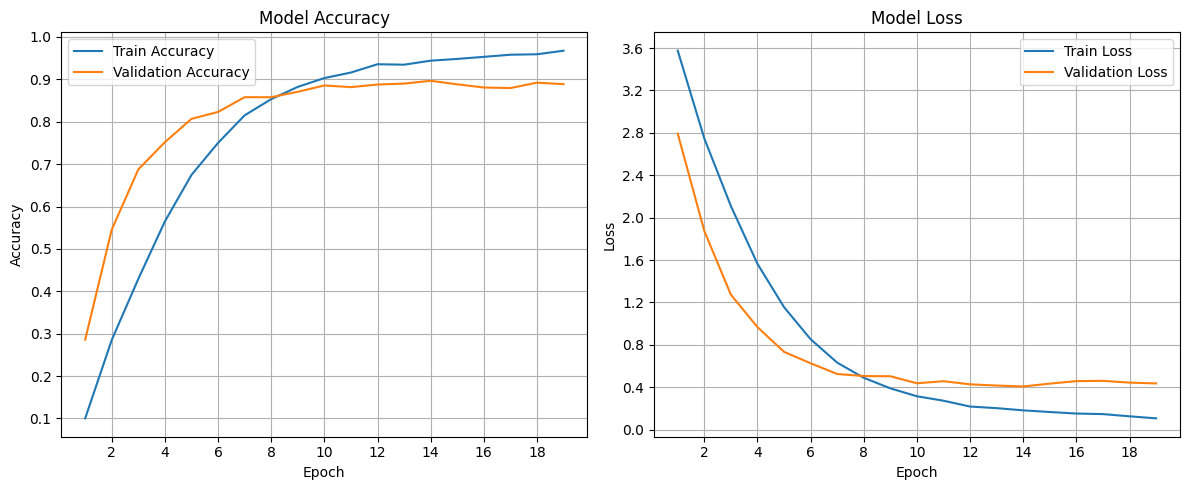

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np

epochs = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['accuracy'], label='Train Accuracy')
plt.plot(epochs, history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=10))
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['loss'], label='Train Loss')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.gca().yaxis.set_major_locator(MaxNLocator(nbins=10))
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

plt.tight_layout()
plt.show()


In [ ]:
import os
train_dir = "Monument-Recognition/Dataset/1.Train"
class_folders = os.listdir(train_dir)
print(f"Total number of classes: {len(class_folders)}")


Total number of classes: 49


## 8. Evaluation on the held-out test set (623 images)

In [ ]:
from tensorflow.keras.models import load_model
model = load_model('model3.h5')

In [ ]:

test_path = "Monument-Recognition/Dataset/Test"


transform = transforms.Compose([
    transforms.Resize((400, 400)),
    transforms.ToTensor()
])


test_dataset = datasets.ImageFolder(test_path, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


test_images, test_labels = next(iter(test_loader))
print("Test batch shape:", test_images.shape)
print("Test batch labels:", test_labels)


Test batch shape: torch.Size([32, 3, 400, 400])
Test batch labels: tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1, 1, 1, 1, 1, 1])


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

# Disable TF functions (use eager mode for debugging)
tf.config.run_functions_eagerly(True)

# Convert the PyTorch test dataset to NumPy arrays
X_test = []
y_test = []

for batch in test_loader:
    images, labels = batch
    images = images.permute(0, 2, 3, 1).numpy()  # Convert to (B, H, W, C)
    labels = labels.numpy()

    X_test.append(images)
    y_test.append(labels)


X_test = np.vstack(X_test).astype(np.float32)
y_test = np.concatenate(y_test)


# One-hot encode labels
num_classes = len(test_dataset.classes)
y_test_cat = to_categorical(y_test, num_classes)

# Double-check shapes
print("X_test shape:", X_test.shape)
print("y_test_cat shape:", y_test_cat.shape)

# Final evaluation
loss, accuracy = model.evaluate(X_test, y_test_cat, verbose=1)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {accuracy:.4f}")


X_test shape: (623, 400, 400, 3)
y_test_cat shape: (623, 49)
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - accuracy: 0.5651 - loss: 2.0295
Test Loss: 1.9779, Test Accuracy: 0.5843


## 9. Sample predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


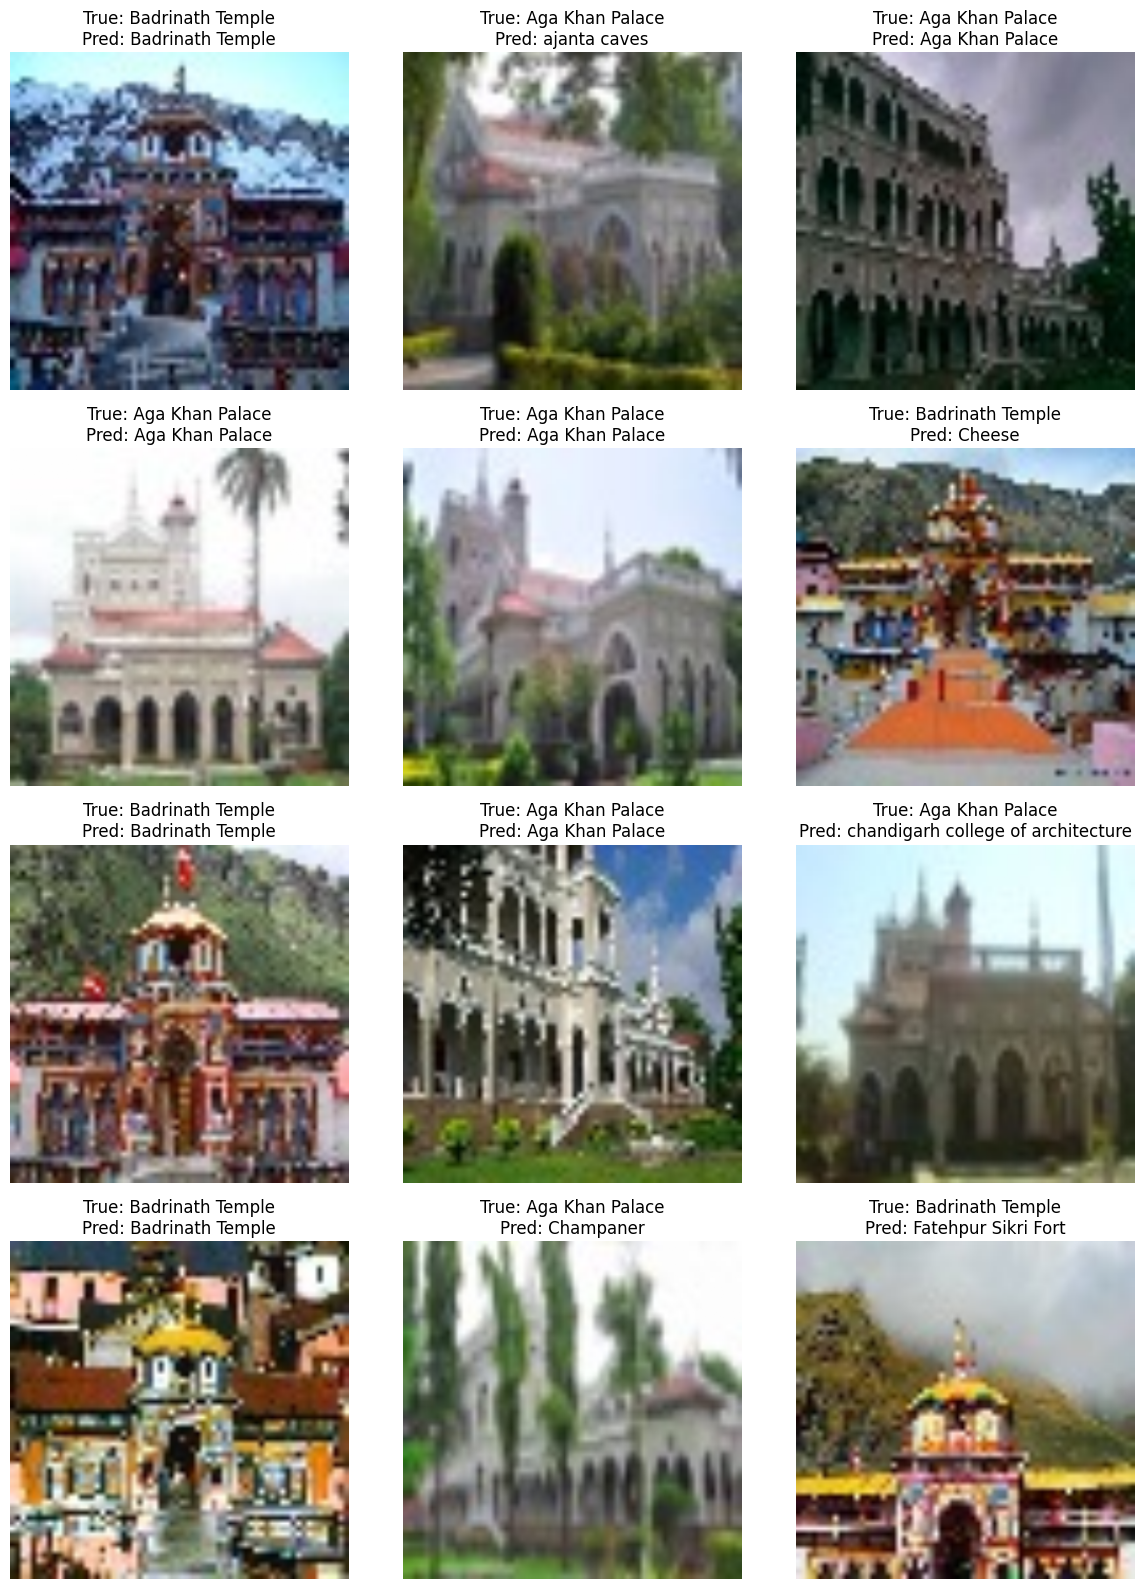

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import random

class_names = test_dataset.classes

def imshow(ax, img, true_label, pred_label):
    img = img.numpy().transpose((1, 2, 0))
    ax.imshow(img)
    ax.set_title(f"True: {class_names[true_label]}\nPred: {class_names[pred_label]}")
    ax.axis('off')

test_iter = iter(test_loader)
images, labels = next(test_iter)


indices = random.sample(range(len(images)), 12)


fig, axes = plt.subplots(4, 3, figsize=(12, 16))
axes = axes.flatten()

for i, idx in enumerate(indices):
    img = images[idx]
    true_label = labels[idx].item()


    img_np = img.numpy().transpose((1, 2, 0))
    img_np = np.expand_dims(img_np, axis=0)

    pred_probs = model.predict(img_np)
    pred_label = np.argmax(pred_probs)

    imshow(axes[i], img, true_label, pred_label)

plt.tight_layout()
plt.show()
